# Two-dimensional London Modeling
Thin-film superconductors are described with the London equations. SOTtools contains a solver for the London equations for simply-connected geometries with an arbitrary number of inlets and outlets. The solver works in current-bias and additionally suports external fields.

We start by defining the mesh for a simple bias-tee.

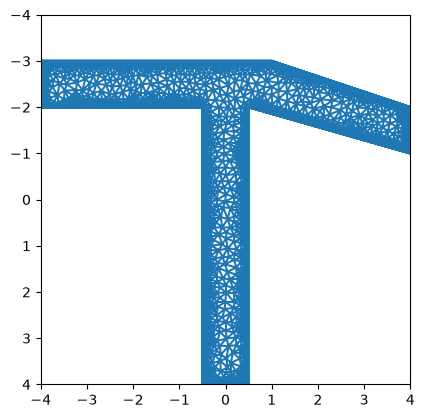

In [1]:
from sottools.mesh import SimplyConnectedCurrentMesh, LondonSolver
import numpy as np
import matplotlib.pyplot as plt

vertices = [
    [ 4.0, -0.5],
    [ 4.0, 0.5],
    [-2.0, 0.5],
    [-1.0, 4.0],
    [-2.0, 4.0],
    [-3.0, 1.0],
    [-3.0, 0.5],
    [-3.0, -4.0],
    [-2.0, -4.0],
    [-2.0, -0.5]
]

segments = [
    [0, 1],
    [1, 2],
    [2, 3],
    [3, 4],
    [4, 5],
    [5, 6],
    [6, 7],
    [7, 8],
    [8, 9],
    [9, 0]
]

BM = SimplyConnectedCurrentMesh.BoundaryMarker

segment_markers = [
    BM.NEUMANN_IN,
    BM.WALL(0),
    BM.WALL(0),
    BM.NEUMANN_OUT,
    BM.WALL(1),
    BM.WALL(1),
    BM.WALL(1),
    BM.NEUMANN_IN,
    BM.WALL(2),
    BM.WALL(2)
]

mesh = SimplyConnectedCurrentMesh(
    vertices,
    segments,
    segment_markers,
    max_area = 0.02,
    refine_distance = 0.02
)

from sottools.utils import meshplotting
fig, ax = plt.subplots(1,1)
meshplotting.plot_mesh(mesh, ax)
ax.set_xlim(-4, 4)
ax.set_ylim(4,-4)
plt.show()

Now we run the LondonSolver. There are three walls (bottom right, top, and bottom left), meaning three boundary values for the streamfunction. Going counter clockwise, an increase in streamfunction means current flowing into the device, whereas a decrease in streamfunction means current flowing out of the device.

In [2]:
solver = LondonSolver(
    mesh=mesh,
    Pearllength=0.3, # Pearl length = lambda^2/2d
    verbose=False
)

boundary_conditions = [
    -5.0, # -3--5 is 2: 2 uA is flowing out of the top right outlet
    -3.0, # 0--3 is 3: 3 uA is flowing out of the bottom left outlet
    0.0 # -5-0 is -5: 5 uA is flowing into the bottom right inlet
]

res = solver.solve(
    boundary_conditions=boundary_conditions
)

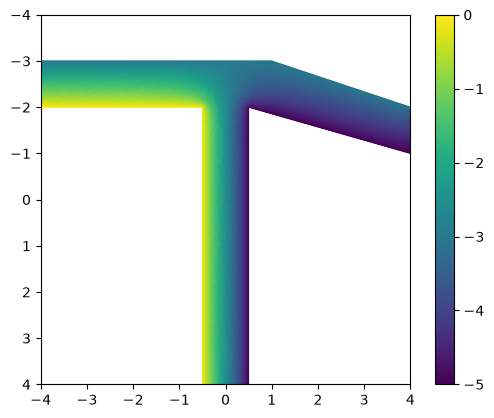

In [3]:
fig, ax = plt.subplots(1,1)
meshplotting.plot_field(mesh, ax, res["streamfunction"])
ax.set_xlim(-4, 4)
ax.set_ylim(4,-4)
plt.show()

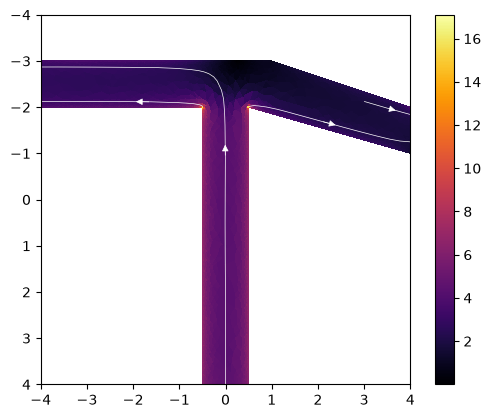

In [4]:
fig, ax = plt.subplots(1,1)
meshplotting.streamplot(
    mesh,
    ax,
    res["Kx"],
    res["Ky"],
    n_grid=256,
    density=0.3,
    cmap='inferno'
)
ax.set_xlim(-4, 4)
ax.set_ylim(4,-4)
plt.show()

All looks good! We can now also convert this to a SQUID image.

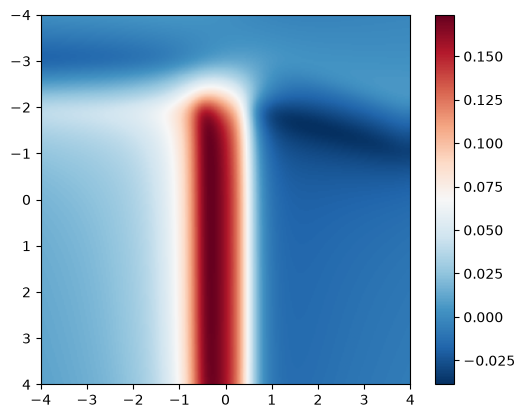

In [5]:
from sottools.forward import Forward2DParameters, Forward2DCurrent, MeshToGrid

rho1 = 0.08
rho2 = 0.25
height = 0.35
phi = np.deg2rad(62.0)

params = Forward2DParameters(
    Nx = 256,
    Ny = 256,
    Lx = 8.0,
    Ly = 8.0,
    rho1=rho1,
    rho2=rho2,
    height=height,
    phi=phi,
    invert_normal=False,
    invert_scan=False
)

m2g = MeshToGrid(mesh, params)
fwd = Forward2DCurrent(params)

image = fwd.forward(*m2g.streamfunction_to_currents(res["streamfunction"]))

fig, ax = plt.subplots(1,1)
im = ax.imshow(image, extent=[-params.Ly/2, params.Ly/2, params.Lx/2, -params.Lx/2], cmap='RdBu_r')
plt.colorbar(im, ax=ax)
plt.show()


Moreover, also the 2D inversion functions still work, as we illustrate here.

In [6]:
SNR = 80
image_noisy = image + np.random.normal(scale=np.ptp(image)/SNR, size=image.shape)

mesh_sol = SimplyConnectedCurrentMesh( # remesh to avoid 'inverse crime'
    vertices,
    segments,
    segment_markers,
    max_area = 0.03,
    refine_distance = 0.03
)
m2g_sol = MeshToGrid(mesh_sol, params)
params_sol = Forward2DParameters(
    Nx = 256,
    Ny = 256,
    Lx = 8.0,
    Ly = 8.0,
    rho1=rho1*1.1, # Little bit of model mismatch
    rho2=rho2*1.1,
    height=height*1.2,
    phi=phi*1.02,
    invert_normal=False,
    invert_scan=False
)
fwd_sol = Forward2DCurrent(params_sol)

from sottools.backward import Inverter2D
inverter = Inverter2D(
    m2g_sol,
    fwd_sol,
    image_noisy,
    lam1 = 1e-8,
    lam2 = 1e-11,
    lam3 = 1e-15
)

fitres = inverter.fit(n_steps=200) # Could be sped up with a convergence checker.

D:\sottools\.venv\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve


D:\sottools\src\sottools\backward.py:1917: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  Mff, Kff @ scipy.sparse.linalg.spsolve(Mff, Kf)


D:\sottools\src\sottools\backward.py:1916: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  scipy.sparse.linalg.spsolve(


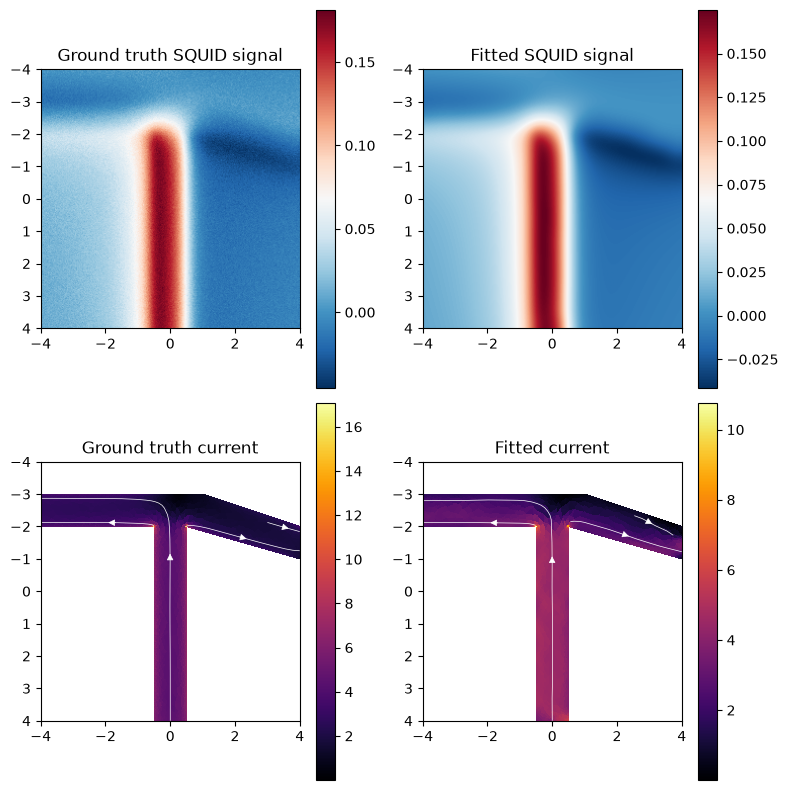

In [7]:
fig, [[ax_truth_signal, ax_fit_signal],[ax_truth_current, ax_fit_current]] = plt.subplots(2,2,figsize=(8,8))

im_truth_signal = ax_truth_signal.imshow(image_noisy, extent=[-params.Ly/2, params.Ly/2, params.Lx/2, -params.Lx/2], cmap='RdBu_r')
plt.colorbar(im_truth_signal, ax=ax_truth_signal)

fit_signal = fwd_sol.forward(*m2g_sol.streamfunction_to_currents(fitres["streamfunction"]))
im_fit_signal = ax_fit_signal.imshow(fit_signal, extent=[-params.Ly/2, params.Ly/2, params.Lx/2, -params.Lx/2], cmap='RdBu_r')
plt.colorbar(im_fit_signal, ax=ax_fit_signal)

im_truth_current = meshplotting.streamplot(
    mesh,
    ax_truth_current,
    res["Kx"],
    res["Ky"],
    n_grid=256,
    density=0.3,
    cmap='inferno'
)
ax_truth_current.set_xlim(-4, 4)
ax_truth_current.set_ylim(4,-4)
im_fit_current = meshplotting.streamplot(
    mesh_sol,
    ax_fit_current,
    fitres["Kx"],
    fitres["Ky"],
    n_grid=256,
    density=0.3,
    cmap='inferno'
)
ax_fit_current.set_xlim(-4, 4)
ax_fit_current.set_ylim(4,-4)
ax_truth_signal.set_title("Ground truth SQUID signal")
ax_fit_signal.set_title("Fitted SQUID signal")
ax_truth_current.set_title("Ground truth current")
ax_fit_current.set_title("Fitted current")
plt.tight_layout()
plt.show()


The reconstruction is rather good, although the edge crowding is underestimated (artifact of both SQUID size and regularization) and the mirroring over the edge gives small artifacts at the mesh edges. In publication-quality reconstructions, one should take the image slightly too large, then crop down.

One key application could be determining the split of current in a T-junction like this. Note that the relative split is accurate, but unless the raw data is perfectly calibrated, the absolute value of the current is not accurate (i.e. it is as accurate as the calibration). The calibration includes both the voltage-to-flux conversion and the SQUID model parameters (height, radius, etc.). In practice, the inlet current is nominally known, and one could even use this as a calibration aid.

Here, the current determination is actually quite far off, but this is natural as we made the SQUID as having 10% more diameter --> a significant overestimation of the flux.

In [8]:
streamfunction_wall_values_sol = [fitres["streamfunction"][mesh_sol.dirichlet_wall_mask(i)][0] for i in range(mesh_sol.N_walls)]
inlet_current_sol = streamfunction_wall_values_sol[2] - streamfunction_wall_values_sol[0]
outlet_current_right_sol = streamfunction_wall_values_sol[1] - streamfunction_wall_values_sol[0]
outlet_current_left_sol = streamfunction_wall_values_sol[2] - streamfunction_wall_values_sol[1]

streamfunction_wall_values_truth = [res["streamfunction"][mesh.dirichlet_wall_mask(i)][0] for i in range(mesh.N_walls)]
inlet_current_truth = streamfunction_wall_values_truth[2] - streamfunction_wall_values_truth[0]
outlet_current_right_truth = streamfunction_wall_values_truth[1] - streamfunction_wall_values_truth[0]
outlet_current_left_truth = streamfunction_wall_values_truth[2] - streamfunction_wall_values_truth[1]

sol_split = outlet_current_right_sol / inlet_current_sol
truth_split = outlet_current_right_truth / inlet_current_truth

print("Solution: Inlet current = {:.2f} uA, right outlet current = {:.2f} uA, left outlet current = {:.2f} uA, right path takes {:.2f}% of the total.".format(
    inlet_current_sol,
    outlet_current_right_sol,
    outlet_current_left_sol,
    sol_split*100
))
print("Ground truth: Inlet current = {:.2f} uA, right outlet current = {:.2f} uA, left outlet current = {:.2f} uA, right path takes {:.2f}% of the total.".format(
    inlet_current_truth,
    outlet_current_right_truth,
    outlet_current_left_truth,
    truth_split*100
))

Solution: Inlet current = 4.46 uA, right outlet current = 1.84 uA, left outlet current = 2.63 uA, right path takes 41.17% of the total.
Ground truth: Inlet current = 5.00 uA, right outlet current = 2.00 uA, left outlet current = 3.00 uA, right path takes 40.00% of the total.
